# Choi 2020 action-state transitions

This notebook derives action-state transition matrices directly from the experimental replay trajectories. It preserves raw action timestamps, reports mixed `ADD+DELETE` events, inserts one `NONE` state after more than five seconds of inactivity, and estimates uncertainty with a cohort/round hierarchical bootstrap.


## Imports and display settings


In [1]:
import sys
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scienceplots  # noqa: F401
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib_inline.backend_inline import set_matplotlib_formats
from netgraph import Graph as NetGraph

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.core.model import ActionType
from network_creation.data.choi_2020 import (
    list_choi_2020_configs,
    load_choi_2020_normalized_data,
    load_choi_2020_replay_data,
)

In [2]:
%matplotlib inline
plt.style.use(["science", "no-latex"])
set_matplotlib_formats("svg", bbox_inches=None)
extra = 4
plt.rcParams.update({
    "font.size": 13 + extra,
    "axes.titlesize": 15 + extra,
    "axes.labelsize": 14 + extra,
    "xtick.labelsize": 11 + extra,
    "ytick.labelsize": 11 + extra,
    "legend.fontsize": 11 + extra,
    "legend.title_fontsize": 12 + extra,
})

## Analysis definition

A pure event containing one or more additions is `ADD`; a pure event containing one or more deletions is `DELETE`. Rare timestamps containing both are retained as `MIXED` for diagnostics, but transition intervals touching them are excluded without bridging across the event.

For pure consecutive events separated by at most the inactivity threshold, the action states transition directly. A longer gap inserts one `NONE` state, yielding `action → NONE → action`. Boundary inactivity before the first action and after the last action is treated the same way. Repeated `NONE → NONE` transitions are not generated.


In [3]:
DATA_ROOT = project_root / "data" / "choi_2020" / "raw"
FIGURE_DIR = (
    project_root / "artifacts" / "figures" / "choi_2020_action_transitions"
)
INACTIVITY_THRESHOLD_SECONDS = 5
THRESHOLD_SECONDS = np.arange(1, 33, dtype=np.int64)
CONFIDENCE_LEVEL = 0.95
N_BOOTSTRAP_RESAMPLES = 4_000
BOOTSTRAP_SEED = 20260828
ILLUSTRATION_SEED = 20260829

STATE_NAMES = ("ADD", "DELETE", "NONE")
STATE_INDEX = {name: index for index, name in enumerate(STATE_NAMES)}
ADD_STATE = STATE_INDEX["ADD"]
DELETE_STATE = STATE_INDEX["DELETE"]
NONE_STATE = STATE_INDEX["NONE"]
MIXED_STATE = -1

STATE_COLORS = {
    "ADD": "#2166ac",
    "DELETE": "#b2182b",
    "NONE": "#6c757d",
}
SCOPE_GROUP_SIZES = {
    "Overall": None,
    "n=10": 10,
    "n=50": 50,
    "n=100": 100,
}

{
    "inactivity_threshold_seconds": INACTIVITY_THRESHOLD_SECONDS,
    "threshold_sensitivity_seconds": (
        int(THRESHOLD_SECONDS[0]), int(THRESHOLD_SECONDS[-1])
    ),
    "bootstrap_resamples": N_BOOTSTRAP_RESAMPLES,
    "confidence_level": CONFIDENCE_LEVEL,
    "illustration_seed": ILLUSTRATION_SEED,
}

{'inactivity_threshold_seconds': 5,
 'threshold_sensitivity_seconds': (1, 32),
 'bootstrap_resamples': 4000,
 'confidence_level': 0.95,
 'illustration_seed': 20260829}

## Raw action events

The existing replay loader converts each recorded link-set update into exact edge additions and deletions while retaining the raw experimental timestamp. No synthetic tail padding is used here. Event-level frames remain in memory for the analysis; only compact summaries are displayed.


In [4]:
@dataclass(frozen=True)
class ActionTrajectory:
    game_index: int
    group_size: int
    agent_id: int
    max_time_s: int
    times_s: tuple[int, ...]
    states: tuple[int, ...]


def state_name(state):
    return "MIXED" if state == MIXED_STATE else STATE_NAMES[state]


def summarize_actions(actions):
    non_pass_actions = tuple(
        action for action in actions if action.type is not ActionType.PASS
    )
    unexpected_types = {
        action.type
        for action in non_pass_actions
        if action.type not in {ActionType.ADD, ActionType.DELETE}
    }
    if unexpected_types:
        raise ValueError(f"unexpected experimental action types: {unexpected_types}")

    n_adds = sum(action.type is ActionType.ADD for action in non_pass_actions)
    n_deletes = sum(
        action.type is ActionType.DELETE for action in non_pass_actions
    )
    if n_adds and n_deletes:
        return MIXED_STATE, n_adds, n_deletes
    if n_adds:
        return ADD_STATE, n_adds, n_deletes
    if n_deletes:
        return DELETE_STATE, n_adds, n_deletes
    return None


In [5]:
available_configs = list_choi_2020_configs(DATA_ROOT)
game_records = []
event_records = []
trajectories = []

for game_index, config in enumerate(available_configs):
    normalized = load_choi_2020_normalized_data(config)
    replay = load_choi_2020_replay_data(
        config, max_steps=normalized.max_step
    )
    cohort_id = (
        f"n{config.group_size}_s{config.session_id}_g{config.group_id}"
    )
    game_records.append({
        "game_index": game_index,
        "cohort_id": cohort_id,
        "group_size": config.group_size,
        "session_id": config.session_id,
        "group_id": config.group_id,
        "round_id": config.round_id,
        "max_time_s": replay.max_step,
    })

    for agent_id, replay_trajectory in replay.trajectories.items():
        times_s = []
        states = []
        for time_s, actions in replay_trajectory.actions_by_step.items():
            summary = summarize_actions(actions)
            if summary is None:
                continue
            state, n_adds, n_deletes = summary
            times_s.append(int(time_s))
            states.append(state)
            event_records.append({
                "game_index": game_index,
                "group_size": config.group_size,
                "agent_id": agent_id,
                "time_s": int(time_s),
                "raw_state": state_name(state),
                "n_adds": n_adds,
                "n_deletes": n_deletes,
                "n_actions": n_adds + n_deletes,
            })

        trajectories.append(ActionTrajectory(
            game_index=game_index,
            group_size=config.group_size,
            agent_id=agent_id,
            max_time_s=replay.max_step,
            times_s=tuple(times_s),
            states=tuple(states),
        ))

game_frame = pd.DataFrame.from_records(game_records).sort_values(
    "game_index", ignore_index=True
)
event_frame = pd.DataFrame.from_records(event_records).sort_values(
    ["game_index", "agent_id", "time_s"], ignore_index=True
)

{
    "games": len(game_frame),
    "cohorts": game_frame["cohort_id"].nunique(),
    "agent_game_trajectories": len(trajectories),
    "raw_action_events": len(event_frame),
}

{'games': 60,
 'cohorts': 12,
 'agent_game_trajectories': 3200,
 'raw_action_events': 101328}

## Raw consecutive-event transitions

Raw transitions connect consecutive action-bearing timestamps for the same game-local agent. They retain mixed endpoints and elapsed time so diagnostics can be computed before applying the inactivity rule.


In [6]:
raw_transition_records = []
for trajectory in trajectories:
    for event_index in range(len(trajectory.times_s) - 1):
        next_event_index = event_index + 1
        from_state = trajectory.states[event_index]
        to_state = trajectory.states[next_event_index]
        from_time_s = trajectory.times_s[event_index]
        to_time_s = trajectory.times_s[next_event_index]
        raw_transition_records.append({
            "game_index": trajectory.game_index,
            "group_size": trajectory.group_size,
            "agent_id": trajectory.agent_id,
            "from_time_s": from_time_s,
            "to_time_s": to_time_s,
            "delta_s": to_time_s - from_time_s,
            "from_state": state_name(from_state),
            "to_state": state_name(to_state),
            "touches_mixed": (
                from_state == MIXED_STATE or to_state == MIXED_STATE
            ),
        })

raw_transition_frame = pd.DataFrame.from_records(
    raw_transition_records
).sort_values(
    ["game_index", "agent_id", "from_time_s"],
    ignore_index=True,
)

In [7]:
summary_records = []
gap_records = []
raw_count_records = []
gap_quantiles = (0.5, 0.9, 0.95, 1.0)
gap_quantile_names = ("median_s", "p90_s", "p95_s", "max_s")

for scope, group_size in SCOPE_GROUP_SIZES.items():
    if group_size is None:
        events = event_frame
        transitions = raw_transition_frame
        games = game_frame
    else:
        events = event_frame[event_frame["group_size"] == group_size]
        transitions = raw_transition_frame[
            raw_transition_frame["group_size"] == group_size
        ]
        games = game_frame[game_frame["group_size"] == group_size]

    n_agent_game_trajectories = sum(
        1
        for trajectory in trajectories
        if group_size is None or trajectory.group_size == group_size
    )
    n_events = len(events)
    n_mixed = int((events["raw_state"] == "MIXED").sum())
    n_multiple = int((events["n_actions"] > 1).sum())
    summary_records.append({
        "scope": scope,
        "n_games": len(games),
        "n_agent_game_trajectories": n_agent_game_trajectories,
        "n_action_events": n_events,
        "n_add_events": int((events["raw_state"] == "ADD").sum()),
        "n_delete_events": int(
            (events["raw_state"] == "DELETE").sum()
        ),
        "n_mixed_events": n_mixed,
        "mixed_event_share": n_mixed / n_events,
        "multiple_action_share": n_multiple / n_events,
    })

    quantile_values = np.quantile(
        transitions["delta_s"].to_numpy(dtype=float), gap_quantiles
    )
    gap_records.append({
        "scope": scope,
        **dict(zip(gap_quantile_names, quantile_values, strict=True)),
    })

    pure_transitions = transitions[~transitions["touches_mixed"]]
    for from_state in ("ADD", "DELETE"):
        for to_state in ("ADD", "DELETE"):
            raw_count_records.append({
                "scope": scope,
                "from_state": from_state,
                "to_state": to_state,
                "count": int(
                    (
                        (pure_transitions["from_state"] == from_state)
                        & (pure_transitions["to_state"] == to_state)
                    ).sum()
                ),
            })

event_summary = pd.DataFrame.from_records(summary_records)
gap_summary = pd.DataFrame.from_records(gap_records)
raw_transition_counts = pd.DataFrame.from_records(raw_count_records)
raw_transition_count_table = raw_transition_counts.pivot(
    index=["scope", "from_state"],
    columns="to_state",
    values="count",
)

display(
    event_summary[[
        "scope",
        "n_games",
        "n_agent_game_trajectories",
        "n_action_events",
        "n_add_events",
        "n_delete_events",
        "n_mixed_events",
        "mixed_event_share",
        "multiple_action_share",
    ]].style.format({
        "mixed_event_share": "{:.3%}",
        "multiple_action_share": "{:.3%}",
    })
)
display(
    gap_summary[["scope", "median_s", "p90_s", "p95_s", "max_s"]]
    .style.format(precision=1)
)
display(raw_transition_count_table)

,scope,n_games,n_agent_game_trajectories,n_action_events,n_add_events,n_delete_events,n_mixed_events,mixed_event_share,multiple_action_share
0,Overall,60,3200,101328,52134,48952,242,0.239%,0.804%
1,n=10,20,200,7443,3787,3618,38,0.511%,0.806%
2,n=50,20,1000,35684,18274,17327,83,0.233%,0.846%
3,n=100,20,2000,58201,30073,28007,121,0.208%,0.778%


,scope,median_s,p90_s,p95_s,max_s
0,Overall,4.0,18.0,32.0,352.0
1,n=10,3.0,16.0,28.0,350.0
2,n=50,3.0,17.0,29.0,330.0
3,n=100,4.0,20.0,33.0,352.0


to_state              ADD  DELETE
scope   from_state               
Overall ADD         17290   33979
        DELETE      31544   14885
n=10    ADD           825    2900
        DELETE       2742     704
n=100   ADD         10578   18968
        DELETE      17465    8991
n=50    ADD          5887   12111
        DELETE      11337    5190

## Illustrative action raster

A seeded random `n=10` persistent cohort and one of its rounds provide a concrete view of the raw action sequences. Each column is one experimental second and each horizontal band is one person: white means no recorded action, blue means `ADD`, and red means `DELETE`. A rare timestamp containing both actions is split into blue and red half-cells. Unlike the transition analysis, white cells here show every inactive second rather than a single inserted `NONE` state.


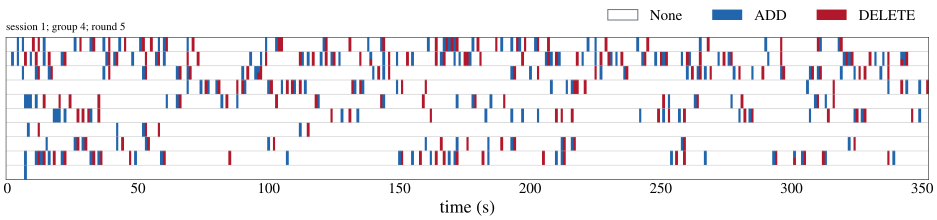

In [8]:
illustration_rng = np.random.default_rng(ILLUSTRATION_SEED)
n10_cohort_ids = np.array(sorted(
    game_frame.loc[game_frame["group_size"] == 10, "cohort_id"].unique()
))
illustration_cohort_id = str(illustration_rng.choice(n10_cohort_ids))
illustration_cohort_games = game_frame[
    game_frame["cohort_id"] == illustration_cohort_id
].sort_values("round_id")
illustration_game = illustration_cohort_games.iloc[
    int(illustration_rng.integers(len(illustration_cohort_games)))
]
illustration_game_index = int(illustration_game["game_index"])
illustration_trajectories = sorted(
    (
        trajectory
        for trajectory in trajectories
        if trajectory.game_index == illustration_game_index
    ),
    key=lambda trajectory: trajectory.agent_id,
)
if len(illustration_trajectories) != 10:
    raise RuntimeError("the illustrative n=10 game must contain 10 people")

raster_rows_per_person = 2
illustration_max_time_s = int(illustration_game["max_time_s"])
action_raster = np.zeros(
    (
        raster_rows_per_person * len(illustration_trajectories),
        illustration_max_time_s + 1,
    ),
    dtype=np.uint8,
)
for person_index, trajectory in enumerate(illustration_trajectories):
    upper_row = raster_rows_per_person * person_index
    lower_row = upper_row + 1
    for time_s, state in zip(trajectory.times_s, trajectory.states, strict=True):
        if state == ADD_STATE:
            action_raster[upper_row:lower_row + 1, time_s] = 1
        elif state == DELETE_STATE:
            action_raster[upper_row:lower_row + 1, time_s] = 2
        elif state == MIXED_STATE:
            action_raster[upper_row, time_s] = 1
            action_raster[lower_row, time_s] = 2
        else:
            raise ValueError(f"unexpected raster state: {state}")

action_raster_colors = (
    "#ffffff", STATE_COLORS["ADD"], STATE_COLORS["DELETE"]
)
action_raster_figure, action_raster_axis = plt.subplots(figsize=(13.5, 3.3))
action_raster_axis.imshow(
    action_raster,
    aspect="auto",
    interpolation="nearest",
    cmap=ListedColormap(action_raster_colors),
    vmin=-0.5,
    vmax=2.5,
)
for boundary in np.arange(1.5, action_raster.shape[0], 2):
    action_raster_axis.axhline(
        boundary, color="#b3b3b3", linewidth=0.5, alpha=0.85
    )
action_raster_axis.set_yticks([])
action_raster_axis.set_xlim(-0.5, illustration_max_time_s + 0.5)
action_raster_axis.set_xlabel("time (s)")
action_raster_axis.tick_params(axis="x", which="both", length=0)
action_raster_axis.text(
    0.0,
    1.035,
    (
        f"session {int(illustration_game['session_id'])}; "
        f"group {int(illustration_game['group_id'])}; "
        f"round {int(illustration_game['round_id'])}"
    ),
    transform=action_raster_axis.transAxes,
    ha="left",
    va="bottom",
    fontsize=11,
)
action_raster_axis.legend(
    handles=[
        Patch(
            facecolor=action_raster_colors[0],
            edgecolor="#6c757d",
            label="None",
        ),
        Patch(facecolor=action_raster_colors[1], label="ADD"),
        Patch(facecolor=action_raster_colors[2], label="DELETE"),
    ],
    loc="lower right",
    bbox_to_anchor=(1.0, 1.005),
    ncol=3,
    frameon=False,
)
action_raster_figure.subplots_adjust(
    left=0.04, right=0.99, bottom=0.20, top=0.80
)
plt.show()

## Thresholded transition matrices

Rows are current states and columns are next states. Matrices are formed from pooled counts and normalized row-wise. The structurally absent `NONE → NONE` cell is retained as zero in calculations and marked as structural in outputs.


In [9]:
def trajectory_transition_counts(trajectory, threshold_seconds):
    counts = np.zeros((len(STATE_NAMES), len(STATE_NAMES)), dtype=np.int64)
    omitted_mixed_intervals = 0
    if not trajectory.times_s:
        return counts, omitted_mixed_intervals

    first_time_s = trajectory.times_s[0]
    first_state = trajectory.states[0]
    if first_time_s > threshold_seconds:
        if first_state == MIXED_STATE:
            omitted_mixed_intervals += 1
        else:
            counts[NONE_STATE, first_state] += 1

    for event_index in range(len(trajectory.times_s) - 1):
        next_event_index = event_index + 1
        from_state = trajectory.states[event_index]
        to_state = trajectory.states[next_event_index]
        if from_state == MIXED_STATE or to_state == MIXED_STATE:
            omitted_mixed_intervals += 1
            continue

        gap_s = (
            trajectory.times_s[next_event_index]
            - trajectory.times_s[event_index]
        )
        if gap_s > threshold_seconds:
            counts[from_state, NONE_STATE] += 1
            counts[NONE_STATE, to_state] += 1
        else:
            counts[from_state, to_state] += 1

    last_time_s = trajectory.times_s[-1]
    last_state = trajectory.states[-1]
    if trajectory.max_time_s - last_time_s > threshold_seconds:
        if last_state == MIXED_STATE:
            omitted_mixed_intervals += 1
        else:
            counts[last_state, NONE_STATE] += 1

    return counts, omitted_mixed_intervals


def build_game_transition_counts(trajectories, thresholds, n_games):
    counts = np.zeros(
        (n_games, len(thresholds), len(STATE_NAMES), len(STATE_NAMES)),
        dtype=np.int64,
    )
    omitted = np.zeros((n_games, len(thresholds)), dtype=np.int64)
    for trajectory in trajectories:
        for threshold_index, threshold_seconds in enumerate(thresholds):
            trajectory_counts, trajectory_omitted = (
                trajectory_transition_counts(trajectory, int(threshold_seconds))
            )
            counts[trajectory.game_index, threshold_index] += trajectory_counts
            omitted[trajectory.game_index, threshold_index] += trajectory_omitted
    return counts, omitted


def normalize_transition_counts(counts):
    values = np.asarray(counts, dtype=np.float64)
    row_totals = values.sum(axis=-1, keepdims=True)
    return np.divide(
        values,
        row_totals,
        out=np.full_like(values, np.nan),
        where=row_totals > 0,
    )


In [10]:
game_transition_counts, game_omitted_intervals = build_game_transition_counts(
    trajectories, THRESHOLD_SECONDS, len(game_frame)
)
selected_threshold_index = int(
    np.flatnonzero(THRESHOLD_SECONDS == INACTIVITY_THRESHOLD_SECONDS).item()
)

observed_counts_by_scope = {}
observed_probabilities_by_scope = {}
omitted_intervals_by_scope = {}
for scope, group_size in SCOPE_GROUP_SIZES.items():
    if group_size is None:
        game_indices = game_frame["game_index"].to_numpy(dtype=np.int64)
    else:
        game_indices = game_frame.loc[
            game_frame["group_size"] == group_size, "game_index"
        ].to_numpy(dtype=np.int64)
    counts = game_transition_counts[game_indices].sum(axis=0)
    observed_counts_by_scope[scope] = counts
    observed_probabilities_by_scope[scope] = normalize_transition_counts(counts)
    omitted_intervals_by_scope[scope] = game_omitted_intervals[
        game_indices
    ].sum(axis=0)

{
    scope: int(omitted[selected_threshold_index])
    for scope, omitted in omitted_intervals_by_scope.items()
}

{'Overall': 475, 'n=10': 73, 'n=50': 165, 'n=100': 237}

## Hierarchical bootstrap uncertainty

Agents interact within games, and the same persistent cohorts are observed over five rounds. Each bootstrap replicate therefore resamples the four cohorts within a group size, then resamples rounds within every selected cohort, while retaining all agents and transitions in a sampled game.

Fixed-threshold cells receive pointwise percentile intervals. Threshold curves receive max-deviation simultaneous bands across 1–32 seconds. With only four cohorts per treatment, these bands should be interpreted as exploratory cluster-bootstrap uncertainty.


In [11]:
def hierarchical_bootstrap_group_counts(
    game_counts, game_frame, group_size, *, n_resamples, rng
):
    group_games = game_frame[game_frame["group_size"] == group_size]
    cohort_ids = tuple(sorted(group_games["cohort_id"].unique()))
    cohort_round_counts = []
    for cohort_id in cohort_ids:
        cohort_games = group_games[
            group_games["cohort_id"] == cohort_id
        ].sort_values("round_id")
        cohort_round_counts.append(
            game_counts[cohort_games["game_index"].to_numpy(dtype=np.int64)]
        )

    round_counts = {len(values) for values in cohort_round_counts}
    if len(round_counts) != 1:
        raise ValueError("all cohorts must contain the same number of rounds")
    n_rounds = round_counts.pop()
    cohort_counts = np.stack(cohort_round_counts, axis=0)
    bootstrap_counts = np.zeros(
        (n_resamples, *game_counts.shape[1:]), dtype=np.int64
    )

    for _ in range(len(cohort_ids)):
        sampled_cohorts = rng.integers(
            0, len(cohort_ids), size=n_resamples
        )
        sampled_rounds = rng.integers(
            0, n_rounds, size=(n_resamples, n_rounds)
        )
        for round_slot in range(n_rounds):
            bootstrap_counts += cohort_counts[
                sampled_cohorts, sampled_rounds[:, round_slot]
            ]
    return bootstrap_counts


def percentile_interval(samples, confidence_level):
    tail_probability = (1.0 - confidence_level) / 2.0
    return np.nanquantile(
        samples,
        (tail_probability, 1.0 - tail_probability),
        axis=0,
    )


def simultaneous_threshold_band(
    observed_probabilities, bootstrap_probabilities, confidence_level
):
    deviations = np.abs(
        bootstrap_probabilities - observed_probabilities[None, ...]
    )
    maximum_deviations = np.nanmax(deviations, axis=1)
    widths = np.nanquantile(
        maximum_deviations, confidence_level, axis=0
    )
    return (
        np.clip(observed_probabilities - widths[None, ...], 0.0, 1.0),
        np.clip(observed_probabilities + widths[None, ...], 0.0, 1.0),
    )


bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_counts_by_scope = {}
for group_size in (10, 50, 100):
    bootstrap_counts_by_scope[f"n={group_size}"] = (
        hierarchical_bootstrap_group_counts(
            game_transition_counts,
            game_frame,
            group_size,
            n_resamples=N_BOOTSTRAP_RESAMPLES,
            rng=bootstrap_rng,
        )
    )
bootstrap_counts_by_scope["Overall"] = np.sum(
    np.stack(
        [bootstrap_counts_by_scope[f"n={group_size}"] for group_size in (10, 50, 100)],
        axis=0,
    ),
    axis=0,
)
bootstrap_probabilities_by_scope = {
    scope: normalize_transition_counts(counts)
    for scope, counts in bootstrap_counts_by_scope.items()
}

fixed_intervals_by_scope = {}
threshold_bands_by_scope = {}
for scope in SCOPE_GROUP_SIZES:
    fixed_intervals_by_scope[scope] = percentile_interval(
        bootstrap_probabilities_by_scope[scope][:, selected_threshold_index],
        CONFIDENCE_LEVEL,
    )
    threshold_bands_by_scope[scope] = simultaneous_threshold_band(
        observed_probabilities_by_scope[scope],
        bootstrap_probabilities_by_scope[scope],
        CONFIDENCE_LEVEL,
    )

{
    "resamples": N_BOOTSTRAP_RESAMPLES,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "cohorts_per_group_size": game_frame.groupby("group_size")["cohort_id"].nunique().to_dict(),
    "rounds_per_cohort": game_frame.groupby("cohort_id")["round_id"].nunique().unique().tolist(),
}

{'resamples': 4000,
 'bootstrap_seed': 20260828,
 'cohorts_per_group_size': {10: 4, 50: 4, 100: 4},
 'rounds_per_cohort': [5]}

## Transition estimates at five seconds


In [12]:
for scope in SCOPE_GROUP_SIZES:
    probabilities = observed_probabilities_by_scope[scope][
        selected_threshold_index
    ]
    interval_low, interval_high = fixed_intervals_by_scope[scope]
    estimates = np.empty((len(STATE_NAMES), len(STATE_NAMES)), dtype=object)
    for from_index, from_state in enumerate(STATE_NAMES):
        for to_index, to_state in enumerate(STATE_NAMES):
            if from_state == "NONE" and to_state == "NONE":
                estimates[from_index, to_index] = "structural"
            else:
                estimates[from_index, to_index] = (
                    f"{probabilities[from_index, to_index]:.3f} "
                    f"[{interval_low[from_index, to_index]:.3f}, "
                    f"{interval_high[from_index, to_index]:.3f}]"
                )
    print(scope)
    display(
        pd.DataFrame(
            estimates,
            index=pd.Index(STATE_NAMES, name="from_state"),
            columns=pd.Index(STATE_NAMES, name="to_state"),
        )
    )

for scope, probabilities in observed_probabilities_by_scope.items():
    supported_rows = np.isfinite(probabilities).all(axis=-1)
    if not np.allclose(
        probabilities.sum(axis=-1)[supported_rows], 1.0
    ):
        raise RuntimeError(f"transition rows do not normalize for {scope}")
    if np.any(observed_counts_by_scope[scope][:, NONE_STATE, NONE_STATE]):
        raise RuntimeError("NONE to NONE must remain structurally absent")

Overall


to_state,ADD,DELETE,NONE
from_state,,,
ADD,"0.229 [0.209, 0.249]","0.494 [0.474, 0.513]","0.278 [0.265, 0.292]"
DELETE,"0.308 [0.294, 0.325]","0.223 [0.204, 0.242]","0.469 [0.452, 0.487]"
NONE,"0.665 [0.653, 0.677]","0.335 [0.323, 0.347]",structural


n=10


to_state,ADD,DELETE,NONE
from_state,,,
ADD,"0.147 [0.122, 0.180]","0.682 [0.618, 0.739]","0.171 [0.131, 0.212]"
DELETE,"0.415 [0.386, 0.442]","0.124 [0.102, 0.150]","0.460 [0.426, 0.497]"
NONE,"0.740 [0.680, 0.805]","0.260 [0.195, 0.320]",structural


n=50


to_state,ADD,DELETE,NONE
from_state,,,
ADD,"0.230 [0.199, 0.261]","0.528 [0.490, 0.559]","0.241 [0.223, 0.270]"
DELETE,"0.326 [0.291, 0.370]","0.224 [0.192, 0.254]","0.450 [0.422, 0.482]"
NONE,"0.680 [0.660, 0.700]","0.320 [0.300, 0.340]",structural


n=100


to_state,ADD,DELETE,NONE
from_state,,,
ADD,"0.238 [0.211, 0.267]","0.449 [0.427, 0.471]","0.313 [0.298, 0.328]"
DELETE,"0.284 [0.275, 0.294]","0.235 [0.208, 0.262]","0.482 [0.459, 0.505]"
NONE,"0.650 [0.636, 0.664]","0.350 [0.336, 0.364]",structural


## State-transition automata

The same estimates are drawn with Netgraph as directed state automata. Black arrow width encodes the transition probability, while state-node colors use the shared action palette. Confidence intervals are not mapped to arrow color or shading; Netgraph edge labels retain each exact estimate and 95% interval.


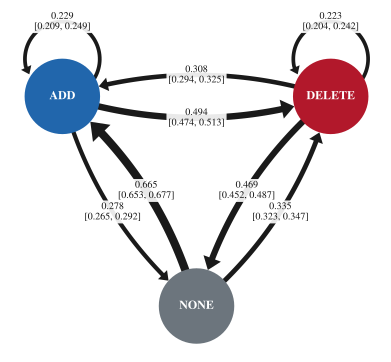

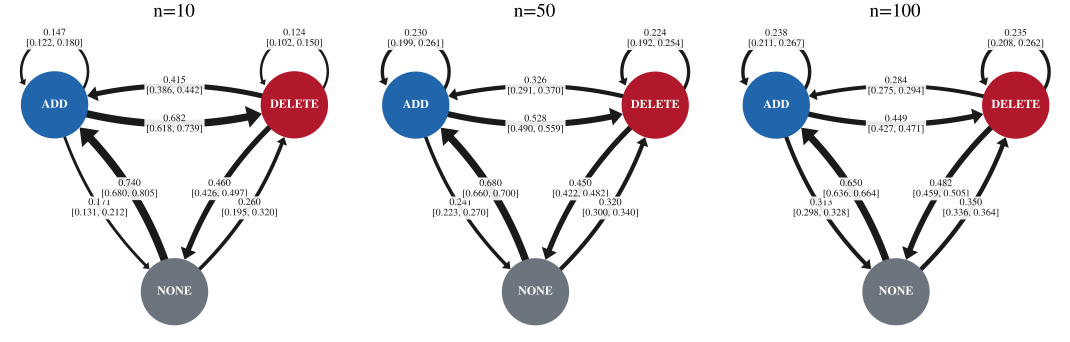

In [13]:
AUTOMATON_NODES = STATE_NAMES
AUTOMATON_EDGES = tuple(
    (from_state, to_state)
    for from_state in STATE_NAMES
    for to_state in STATE_NAMES
    if not (from_state == "NONE" and to_state == "NONE")
)
AUTOMATON_POSITIONS = {
    "ADD": np.array((0.18, 0.70)),
    "DELETE": np.array((0.82, 0.70)),
    "NONE": np.array((0.50, 0.20)),
}
AUTOMATON_ORIGIN = (-0.16, -0.14)
AUTOMATON_SCALE = (1.32, 1.20)


def probability_edge_width(probability):
    return 0.35 + 2.4 * probability


def draw_transition_automaton(axis, scope):
    probabilities = observed_probabilities_by_scope[scope][
        selected_threshold_index
    ]
    interval_low, interval_high = fixed_intervals_by_scope[scope]
    edge_widths = {}
    edge_labels = {}
    for edge in AUTOMATON_EDGES:
        from_index = STATE_INDEX[edge[0]]
        to_index = STATE_INDEX[edge[1]]
        probability = probabilities[from_index, to_index]
        low = interval_low[from_index, to_index]
        high = interval_high[from_index, to_index]
        edge_widths[edge] = probability_edge_width(probability)
        edge_labels[edge] = (
            f"{probability:.3f}\n[{low:.3f}, {high:.3f}]"
        )

    graph = NetGraph(
        AUTOMATON_EDGES,
        nodes=AUTOMATON_NODES,
        node_layout={
            node: position.copy()
            for node, position in AUTOMATON_POSITIONS.items()
        },
        node_size=9.0,
        node_color=STATE_COLORS,
        node_edge_color=STATE_COLORS,
        node_edge_width=0.7,
        node_zorder=3,
        node_labels={state: state for state in STATE_NAMES},
        node_label_fontdict={
            "size": 12,
            "fontweight": "bold",
            "color": "white",
        },
        edge_layout="arc",
        edge_layout_kwargs={"rad": 0.16},
        edge_width=edge_widths,
        edge_color="#1a1a1a",
        edge_alpha=1.0,
        edge_zorder=2,
        arrows=True,
        edge_labels=edge_labels,
        edge_label_position=0.5,
        edge_label_rotate=False,
        edge_label_fontdict={
            "size": 10,
            "color": "#111111",
            "bbox": {
                "boxstyle": "round,pad=0.18",
                "edgecolor": "none",
                "facecolor": "white",
                "alpha": 0.90,
            },
        },
        origin=AUTOMATON_ORIGIN,
        scale=AUTOMATON_SCALE,
        ax=axis,
    )
    if scope != "Overall":
        axis.set_title(scope)
    return graph


overall_automaton_figure, overall_automaton_axis = plt.subplots(
    figsize=(6.3, 5.2)
)
overall_automaton_graph = draw_transition_automaton(
    overall_automaton_axis, "Overall"
)
overall_automaton_figure.subplots_adjust(
    left=0.03, right=0.97, bottom=0.03, top=0.98
)

group_automata_figure, group_automata_axes = plt.subplots(
    1, 3, figsize=(15.5, 5.0)
)
group_automaton_graphs = {}
for axis, scope in zip(
    group_automata_axes, ("n=10", "n=50", "n=100"), strict=True
):
    group_automaton_graphs[scope] = draw_transition_automaton(axis, scope)
group_automata_figure.subplots_adjust(
    left=0.02, right=0.98, bottom=0.04, top=0.92, wspace=0.03
)
plt.show()

## Threshold sensitivity from 1 to 32 seconds

Each shaded region is a 95% max-deviation bootstrap band simultaneous over the displayed thresholds for that transition. The dashed vertical line marks the selected five-second threshold.


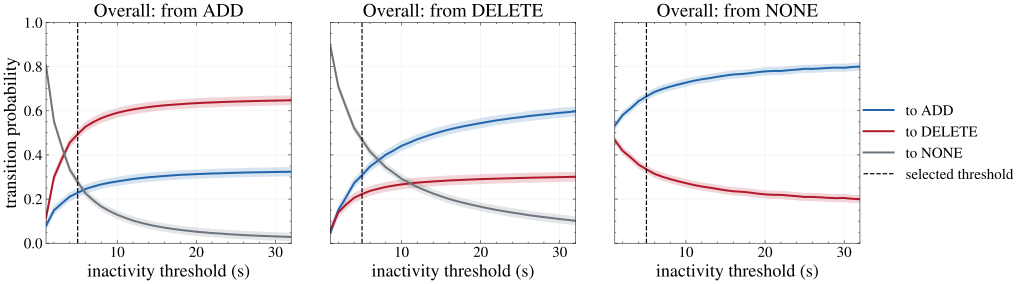

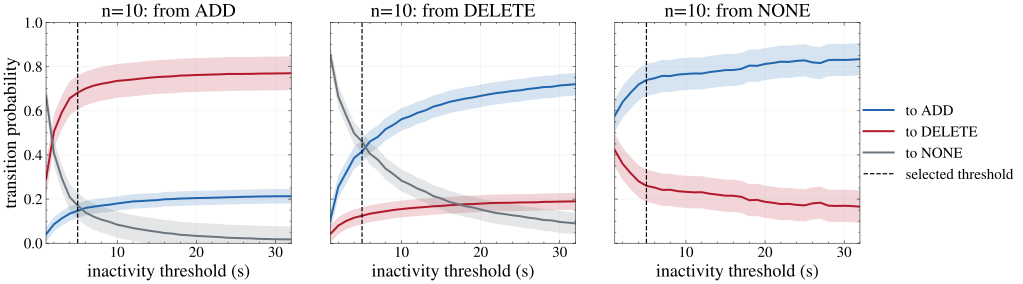

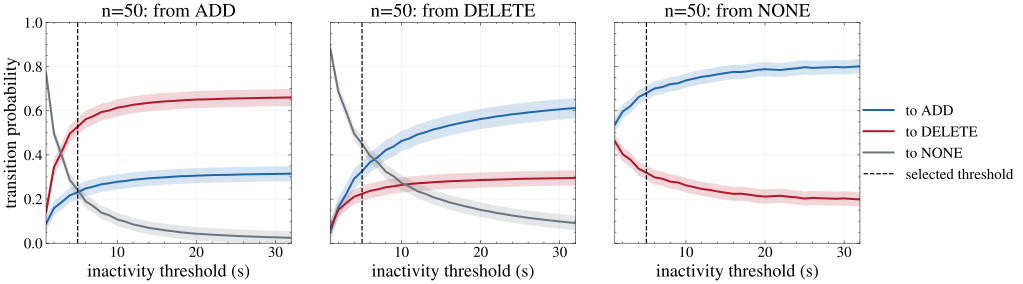

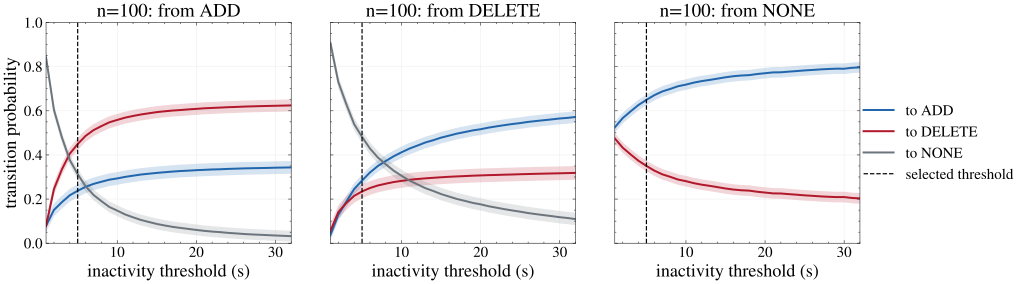

In [14]:
def plot_threshold_sensitivity(scope):
    probabilities = observed_probabilities_by_scope[scope]
    band_low, band_high = threshold_bands_by_scope[scope]
    figure, axes = plt.subplots(
        1, 3, figsize=(14.5, 4.2), sharex=True, sharey=True
    )
    for from_index, axis in enumerate(axes):
        for to_index, to_state in enumerate(STATE_NAMES):
            if from_index == NONE_STATE and to_index == NONE_STATE:
                continue
            color = STATE_COLORS[to_state]
            axis.plot(
                THRESHOLD_SECONDS,
                probabilities[:, from_index, to_index],
                color=color,
                linewidth=2.0,
                label=f"to {to_state}",
            )
            axis.fill_between(
                THRESHOLD_SECONDS,
                band_low[:, from_index, to_index],
                band_high[:, from_index, to_index],
                color=color,
                alpha=0.18,
                linewidth=0,
            )
        axis.axvline(
            INACTIVITY_THRESHOLD_SECONDS,
            color="black",
            linestyle="--",
            linewidth=1.2,
            label="selected threshold",
        )
        axis.set_title(f"{scope}: from {STATE_NAMES[from_index]}")
        axis.set_xlabel("inactivity threshold (s)")
        axis.set_xlim(THRESHOLD_SECONDS[0], THRESHOLD_SECONDS[-1])
        axis.set_ylim(0.0, 1.0)
        axis.grid(alpha=0.25)
    axes[0].set_ylabel("transition probability")
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(
        handles, labels, loc="center right", bbox_to_anchor=(1.0, 0.5)
    )
    figure.subplots_adjust(
        left=0.06, right=0.84, bottom=0.17, top=0.90, wspace=0.16
    )
    return figure


sensitivity_figures = {}
for scope in SCOPE_GROUP_SIZES:
    sensitivity_figure = plot_threshold_sensitivity(scope)
    sensitivity_figures[scope] = sensitivity_figure
    display(sensitivity_figure)
    plt.close(sensitivity_figure)

## Directional action-transition contrast

Writing ADD as $A$ and DELETE as $D$, the time-dependent contrast $\Delta(s) = P_s(D \mid A) - P_s(A \mid D)$ compares the two directions at inactivity threshold $s$ seconds. Each hierarchical-bootstrap replicate computes both probabilities from the same resampled counts before taking their difference. The simultaneous band is based on the maximum absolute bootstrap deviation of this contrast over all thresholds, rather than on differences between separate confidence-band endpoints.


At s=5, the contrast is 0.185474 (approximately 0.186).
The simultaneous 95% band remains above zero across all thresholds.


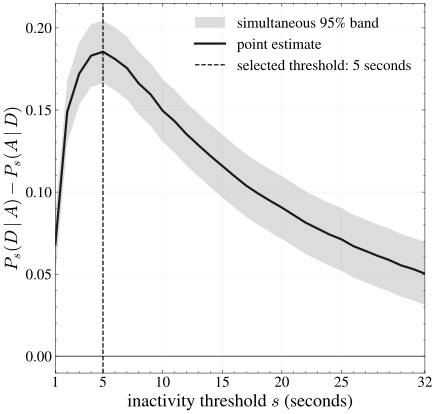

In [16]:
overall_probabilities = observed_probabilities_by_scope["Overall"]
overall_bootstrap_probabilities = bootstrap_probabilities_by_scope["Overall"]
action_contrast = (
    overall_probabilities[:, ADD_STATE, DELETE_STATE]
    - overall_probabilities[:, DELETE_STATE, ADD_STATE]
)
bootstrap_action_contrast = (
    overall_bootstrap_probabilities[:, :, ADD_STATE, DELETE_STATE]
    - overall_bootstrap_probabilities[:, :, DELETE_STATE, ADD_STATE]
)
contrast_maximum_deviations = np.nanmax(
    np.abs(bootstrap_action_contrast - action_contrast[None, :]), axis=1
)
contrast_band_half_width = np.nanquantile(
    contrast_maximum_deviations, CONFIDENCE_LEVEL
)
contrast_band_low = action_contrast - contrast_band_half_width
contrast_band_high = action_contrast + contrast_band_half_width
selected_contrast = float(action_contrast[selected_threshold_index])
reported_selected_contrast = 0.186
if not np.isclose(selected_contrast, reported_selected_contrast, atol=1e-3):
    raise RuntimeError(
        f"expected a five-second contrast of 0.186, got {selected_contrast:.6f}"
    )

point_ordering_persistent = bool(np.all(action_contrast > 0.0))
simultaneous_band_above_zero = bool(np.all(contrast_band_low > 0.0))
if simultaneous_band_above_zero:
    contrast_interpretation = (
        "The simultaneous 95% band remains above zero across all thresholds."
    )
elif point_ordering_persistent:
    contrast_interpretation = (
        "The point-estimate ordering persists across all thresholds, but the "
        "simultaneous 95% band includes zero."
    )
else:
    contrast_interpretation = (
        "The point-estimate ordering does not persist across all thresholds."
    )
print(
    f"At s=5, the contrast is {selected_contrast:.6f} "
    f"(approximately {reported_selected_contrast:.3f})."
)
print(contrast_interpretation)

contrast_figure, contrast_axis = plt.subplots(figsize=(6.5, 6.5))
contrast_axis.fill_between(
    THRESHOLD_SECONDS,
    contrast_band_low,
    contrast_band_high,
    color="#b3b3b3",
    alpha=0.45,
    linewidth=0,
    label="simultaneous 95% band",
)
contrast_axis.plot(
    THRESHOLD_SECONDS,
    action_contrast,
    color="#1a1a1a",
    linewidth=2.2,
    label="point estimate",
)
contrast_axis.axhline(0.0, color="#4d4d4d", linewidth=1.0)
contrast_axis.axvline(
    INACTIVITY_THRESHOLD_SECONDS,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="selected threshold: 5 seconds",
)
contrast_axis.set_xlim(THRESHOLD_SECONDS[0], THRESHOLD_SECONDS[-1])
contrast_axis.set_xticks((1, 5, 10, 15, 20, 25, 32))
contrast_axis.set_xlabel(r"inactivity threshold $s$ (seconds)")
contrast_axis.set_ylabel(r"$P_s(D\mid A)-P_s(A\mid D)$")
contrast_axis.set_box_aspect(1)
contrast_axis.grid(alpha=0.25)
contrast_axis.legend(frameon=False)
contrast_figure.tight_layout()
plt.show()

## Export figures

Only figures are exported beneath `artifacts/`, which is ignored by Git. The concise tables above remain notebook outputs and are intentionally not written to disk. Figures have no overall title; panel identifiers remain where needed.


In [17]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figures_by_name = {
    "illustrative_action_raster_n10.pdf": action_raster_figure,
    "add_delete_transition_contrast_by_threshold.pdf": contrast_figure,
    (
        f"action_transition_automaton_overall_"
        f"{INACTIVITY_THRESHOLD_SECONDS}s.pdf"
    ): overall_automaton_figure,
    (
        f"action_transition_automata_by_group_size_"
        f"{INACTIVITY_THRESHOLD_SECONDS}s.pdf"
    ): group_automata_figure,
}
for scope, figure in sensitivity_figures.items():
    scope_slug = scope.lower().replace("=", "-")
    figures_by_name[
        f"transition_threshold_sensitivity__{scope_slug}.pdf"
    ] = figure

for filename, figure in figures_by_name.items():
    path = FIGURE_DIR / filename
    if figure is contrast_figure:
        with plt.rc_context({"savefig.bbox": None}):
            figure.savefig(path, format="pdf", dpi=300)
    else:
        figure.savefig(path, format="pdf", dpi=300, bbox_inches="tight")
    plt.close(figure)

print(
    f"Saved {len(figures_by_name)} PDFs to "
    f"{FIGURE_DIR.relative_to(project_root)}"
)

Saved 8 PDFs to artifacts/figures/choi_2020_action_transitions
